# **Import Requirements**

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
df = pd.read_csv("../data/processed/credit_card_clean.csv")

In [3]:
df.sample(5)

,cust_id,balance,balance_frequency,purchases,oneoff_purchases,installments_purchases,cash_advance,purchases_frequency,oneoff_purchases_frequency,purchases_installments_frequency,cash_advance_frequency,cash_advance_trx,purchases_trx,credit_limit,payments,minimum_payments,prc_full_payment,tenure
4166,C14282,1032.031399,1.000000,0.00,0.00,0.00,1143.502627,0.000000,0.000000,0.000000,0.166667,4,0,1200.0,239.189487,613.232178,0.0,12
1021,C11056,380.384776,0.545455,1188.00,1188.00,0.00,0.000000,0.083333,0.083333,0.000000,0.000000,0,2,9000.0,2461.320337,158.339807,0.0,12
3914,C14024,9.906062,0.909091,202.30,0.00,202.30,0.000000,0.909091,0.000000,0.818182,0.000000,0,10,1500.0,195.626150,150.087965,0.0,11
8278,C18499,48.487138,0.818182,261.81,0.00,261.81,0.000000,0.666667,0.000000,0.500000,0.000000,0,8,1000.0,231.475316,156.323105,0.0,12
371,C10383,8806.866629,1.000000,1490.94,0.02,1490.92,2813.063846,1.000000,0.166667,1.000000,0.166667,4,25,9000.0,2116.662516,3598.719728,0.0,12


In [4]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 8950 entries, 0 to 8949
Data columns (total 18 columns):
 #   Column                            Non-Null Count  Dtype  
---  ------                            --------------  -----  
 0   cust_id                           8950 non-null   str    
 1   balance                           8950 non-null   float64
 2   balance_frequency                 8950 non-null   float64
 3   purchases                         8950 non-null   float64
 4   oneoff_purchases                  8950 non-null   float64
 5   installments_purchases            8950 non-null   float64
 6   cash_advance                      8950 non-null   float64
 7   purchases_frequency               8950 non-null   float64
 8   oneoff_purchases_frequency        8950 non-null   float64
 9   purchases_installments_frequency  8950 non-null   float64
 10  cash_advance_frequency            8950 non-null   float64
 11  cash_advance_trx                  8950 non-null   int64  
 12  purchases_trx    

In [5]:
df[['purchases_frequency', 'oneoff_purchases_frequency', 'purchases_installments_frequency']].head()

,purchases_frequency,oneoff_purchases_frequency,purchases_installments_frequency
0,0.166667,0.000000,0.083333
1,0.000000,0.000000,0.000000
2,1.000000,1.000000,0.000000
3,0.083333,0.083333,0.000000
4,0.083333,0.083333,0.000000


# **Feature Engineering**

## Feature Selection

### Drop cust_id

In [6]:
df['cust_id'].to_csv('../data/processed/cust_id.csv', index=False)

In [7]:
df = df.drop(columns='cust_id')
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 8950 entries, 0 to 8949
Data columns (total 17 columns):
 #   Column                            Non-Null Count  Dtype  
---  ------                            --------------  -----  
 0   balance                           8950 non-null   float64
 1   balance_frequency                 8950 non-null   float64
 2   purchases                         8950 non-null   float64
 3   oneoff_purchases                  8950 non-null   float64
 4   installments_purchases            8950 non-null   float64
 5   cash_advance                      8950 non-null   float64
 6   purchases_frequency               8950 non-null   float64
 7   oneoff_purchases_frequency        8950 non-null   float64
 8   purchases_installments_frequency  8950 non-null   float64
 9   cash_advance_frequency            8950 non-null   float64
 10  cash_advance_trx                  8950 non-null   int64  
 11  purchases_trx                     8950 non-null   int64  
 12  credit_limit     

### Drop Fitur Rendundan

In [8]:
df = df.drop(columns=["oneoff_purchases", "installments_purchases", "purchases_frequency"])

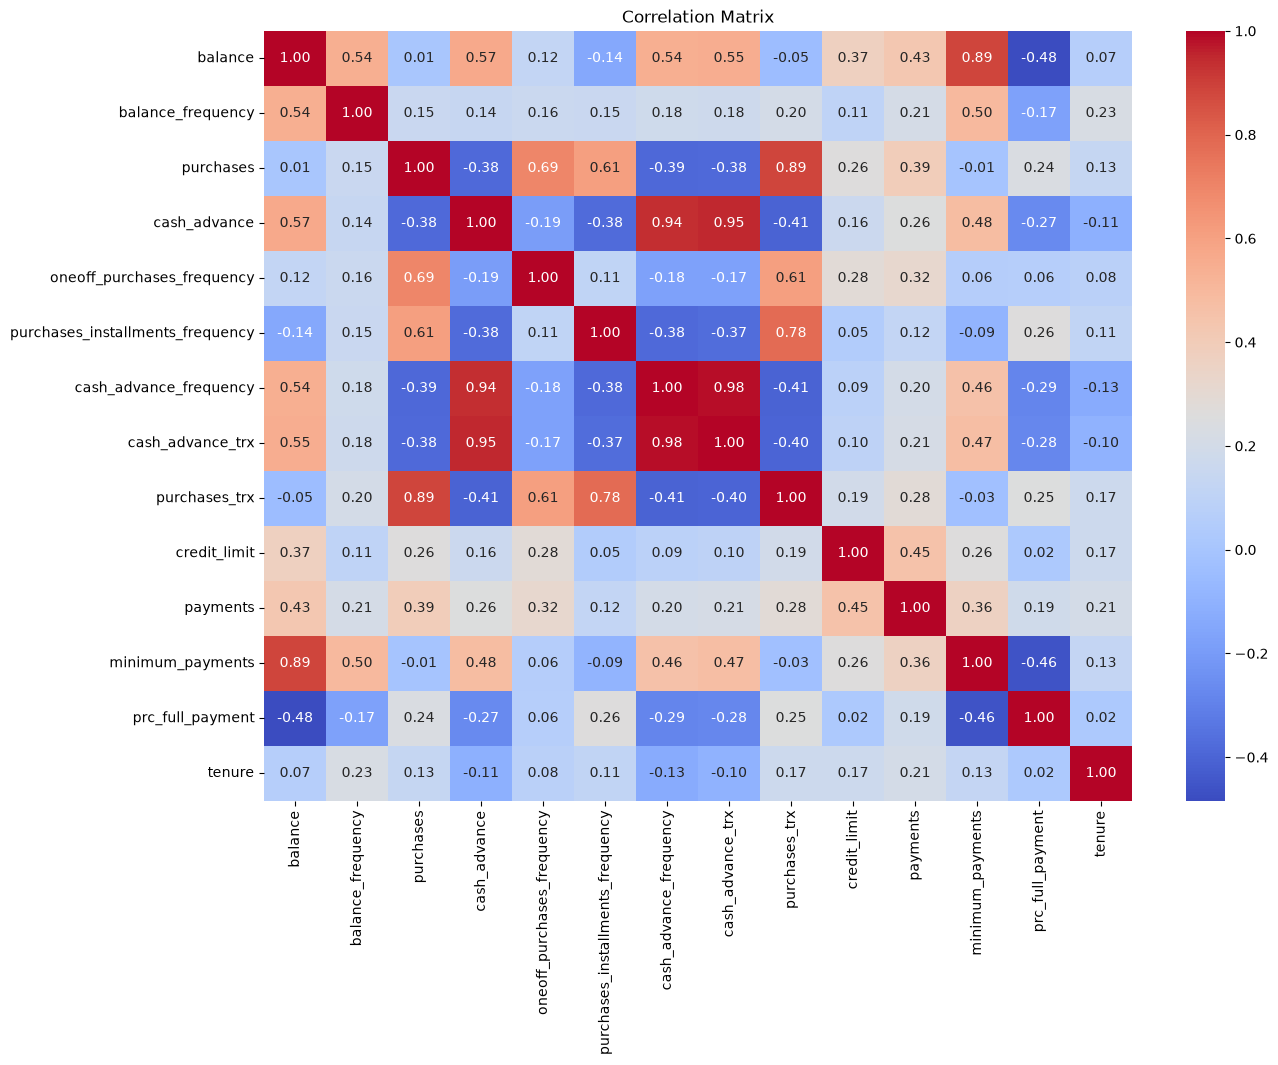

In [9]:
plt.figure(figsize=(14, 10))
sns.heatmap(
    df.corr(method='spearman'),
    annot=True,
    cmap='coolwarm',
    fmt='.2f')
plt.title('Correlation Matrix')
plt.show()

In [10]:
print("Credit Limit = 0:", (df['credit_limit'] == 0).sum())
print("Purchases TRX = 0:", (df['purchases_trx'] == 0).sum())

Credit Limit = 0: 0
Purchases TRX = 0: 2044


## Fitur Baru

### Persentase Penggunaan Kredit

In [11]:
df['credit_utilization'] = (df['balance']/df['credit_limit'])
cap_util = df['credit_utilization'].quantile(0.999)
df['credit_utilization'] = df['credit_utilization'].clip(upper=cap_util)

In [12]:
df['credit_utilization'].describe()

count    8950.000000
mean        0.386931
std         0.352488
min         0.000000
25%         0.041494
50%         0.302720
75%         0.717571
max         1.325289
Name: credit_utilization, dtype: float64

In [13]:
df[['balance','credit_limit','credit_utilization']].sample(5)

,balance,credit_limit,credit_utilization
3547,3690.855584,9500.0,0.388511
4993,125.793836,1000.0,0.125794
7293,1242.886266,4000.0,0.310722
2846,2221.252825,7000.0,0.317322
2372,19.112841,1000.0,0.019113


### Payment Ratio

In [14]:
pr = df['payments'] / df['minimum_payments']


cap = pr.replace([np.inf, -np.inf], np.nan).quantile(0.99)   

df['payment_ratio'] = pr

df.loc[(df['payments'] == 0) & (df['minimum_payments'] == 0), 'payment_ratio'] = 0
df.loc[(df['payments'] > 0)  & (df['minimum_payments'] == 0), 'payment_ratio'] = cap

df['payment_ratio'] = df['payment_ratio'].clip(upper=cap)

In [15]:
df['payment_ratio'].describe()

count    8950.000000
mean        5.447186
std         8.679026
min         0.000000
25%         0.917716
50%         2.054462
75%         6.163540
max        49.984515
Name: payment_ratio, dtype: float64

# **Save Dataset**

In [16]:
df = df.drop(columns=['purchases_trx', 'cash_advance_trx'])

In [17]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 8950 entries, 0 to 8949
Data columns (total 14 columns):
 #   Column                            Non-Null Count  Dtype  
---  ------                            --------------  -----  
 0   balance                           8950 non-null   float64
 1   balance_frequency                 8950 non-null   float64
 2   purchases                         8950 non-null   float64
 3   cash_advance                      8950 non-null   float64
 4   oneoff_purchases_frequency        8950 non-null   float64
 5   purchases_installments_frequency  8950 non-null   float64
 6   cash_advance_frequency            8950 non-null   float64
 7   credit_limit                      8950 non-null   float64
 8   payments                          8950 non-null   float64
 9   minimum_payments                  8950 non-null   float64
 10  prc_full_payment                  8950 non-null   float64
 11  tenure                            8950 non-null   int64  
 12  credit_utilizatio

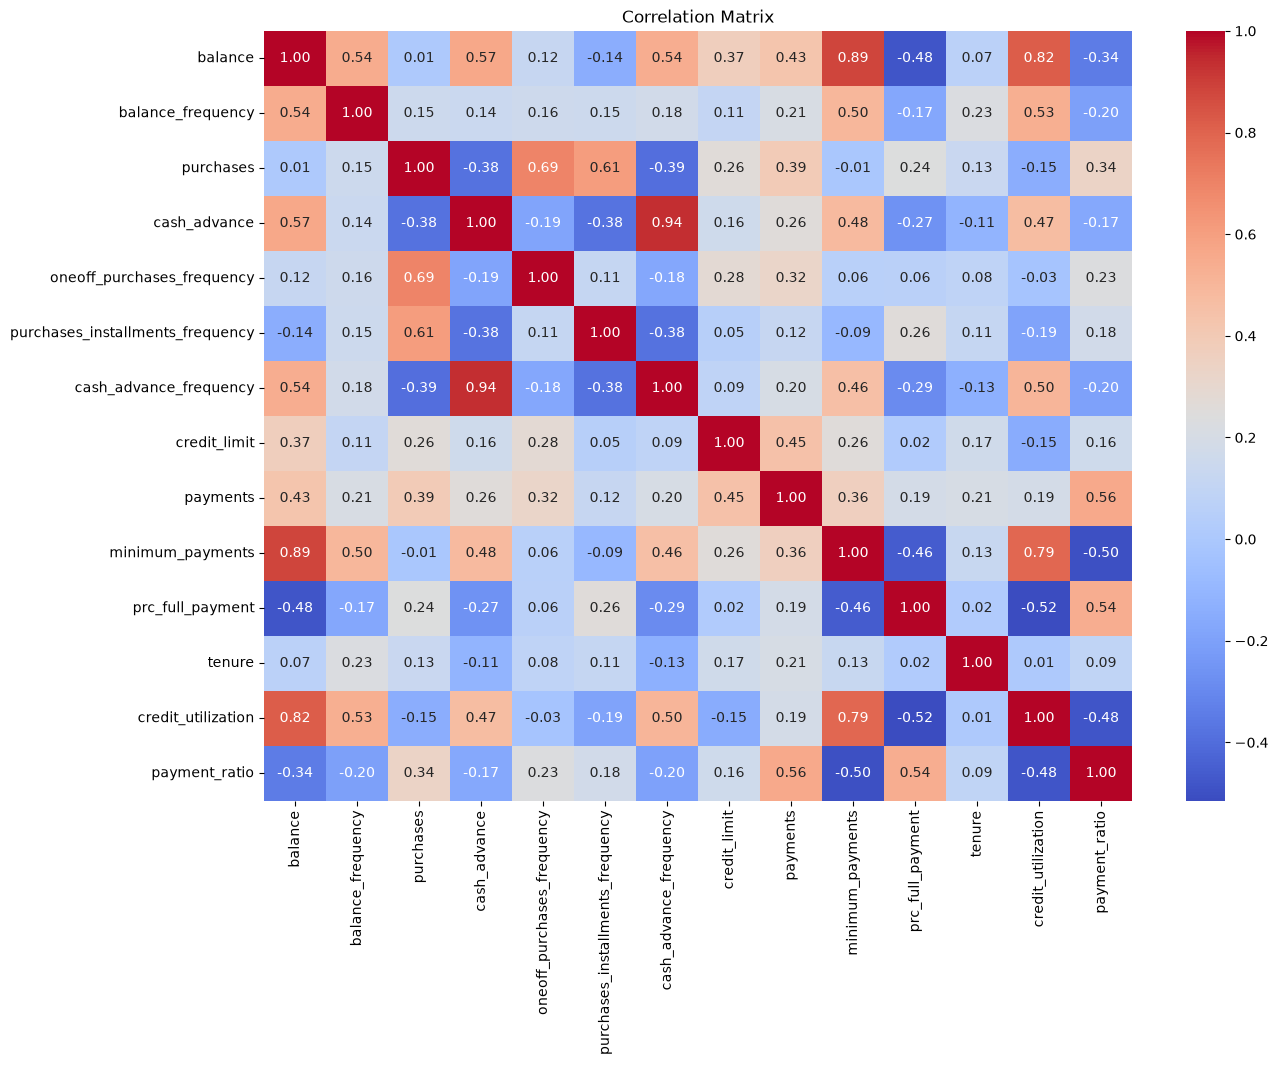

In [18]:
plt.figure(figsize=(14, 10))
sns.heatmap(
    df.corr(method='spearman'),
    annot=True,
    cmap='coolwarm',
    fmt='.2f')
plt.title('Correlation Matrix')
plt.show()

In [19]:
df.to_csv('../data/processed/credit_card_fe.csv', index=False)